# QAOA-in-QAOA: block patterns and global orientations

**Version 0.1.0rc2.** The notebook demonstrates the base hierarchy: a local spin
pattern inside a block, one free block orientation, the exact metagraph and the
reconstruction of the source vertices.

This is not LS-RQAOA: what is selected here is a whole discrete block pattern,
not a pair correlation. The local cut and the constant part `Delta b` are
different quantities.

In [1]:
from pathlib import Path
from copy import deepcopy
import json
import subprocess
import sys
import tempfile

import numpy as np

import QA_max_cut_lib
from QA_max_cut_lib import (
    WeightedGraph, QAOAInQAOACPU, QAOAInQAOAGPU, tools,
)
from QA_max_cut_lib.solvers.hierarchy_components import project_blocks
from QA_max_cut_lib.solvers.gpu_state import gpu_available

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
print(QA_max_cut_lib.__version__)
print("package:", Path(QA_max_cut_lib.__file__).resolve())
assert QA_max_cut_lib.__version__ == "0.1.0a7"
print("gpu_available:", gpu_available())

0.1.0a7
package: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\.venv\Lib\site-packages\QA_max_cut_lib\__init__.py


gpu_available: True


## 1. One block: pattern and flip

First the exact formula is checked on the control graph from the assignment.
Blocks `[10,30]` and `[80,101]` have patterns `(+1,-1)`. The metagraph holds the
weight `-2`, `Delta b=10`, and `C_original=Delta b+C_meta` for all four
orientations.

In [2]:
graph = WeightedGraph(
    [(10,30,2),(80,101,3),(10,80,5),(10,101,1),(30,80,4),(30,101,-2)],
    nodes=[10,30,80,101],
)
blocks = [(10,30),(80,101)]
patterns = {10:{10:1,30:-1}, 80:{80:1,101:-1}}
meta, delta_b, records = project_blocks(graph, blocks, patterns)
print("meta nodes:", meta.nodes)
print("meta edges:", meta.edges)
print("Delta b:", delta_b)
for tau10, tau80 in ((-1,-1),(-1,1),(1,-1),(1,1)):
    solution = {
        10: patterns[10][10]*tau10, 30: patterns[10][30]*tau10,
        80: patterns[80][80]*tau80, 101: patterns[80][101]*tau80,
    }
    print(tau10, tau80, graph.cut_value(solution), delta_b + meta.cut_value({10:tau10,80:tau80}))
assert meta.edges == ((10,80,-2.0),)
assert delta_b == 10.0

meta nodes: (10, 80)
meta edges: ((10, 80, -2.0),)
Delta b: 10.0
-1 -1 10.0 10.0
-1 1 8.0 8.0
1 -1 8.0 8.0
1 1 10.0 10.0


## 2. Several levels of real QAOA

At every level the local problems solve only the induced block. After readout the
pattern is normalized by the anchor, and `GraphReducer` applies `N_l-K` exact
constraints to the whole current graph.

In [3]:
edges = [
    (0,1,1),(1,2,-2),(2,3,2),(3,4,1),(4,5,-1),(5,6,2),(6,7,1),
    (0,7,-2),(0,3,1),(1,4,2),(2,5,-1),(3,6,1),(4,7,-2),
]
graph8 = WeightedGraph(edges, nodes=list(range(8)))
config = tools.load_json(PROJECT / "configs/solvers/qaoa_in_qaoa_cpu.json")
config.pop("save", None)
config["num_treads"] = 1
config["parameters"]["finish_at"] = 2
config["local_solver"]["parameters"]["max_vertices"] = 2
config["local_solver"]["optimizer"]["parameters"]["max_steps"] = 1
config["partitioner"]["parameters"]["max_size"] = 2
solver = QAOAInQAOACPU(config)
solution = solver.solve(graph8, report=0, logs=0)
print("solution:", solution)
print("cut:", solver.cut_value, "levels:", solver.levels_completed)
print("source:", solver.solution_source, "resources:", solver.resources)
assert set(solution) == set(graph8.nodes)
assert solver.levels_completed >= 2
assert solver.solution_source == "exact_finisher"
assert abs(solver.cut_value - graph8.cut_value(solution)) < 1e-9

solution: {0: 1, 2: 1, 5: 1, 1: -1, 6: -1, 7: 1, 3: -1, 4: 1}
cut: 8.0 levels: 2
source: exact_finisher resources: {'shots_used': 0, 'training_shots': 0, 'readout_shots': 0, 'local_solver_calls': 6, 'local_tasks_total': 6, 'primitive_reductions_completed': 6, 'levels_completed': 2, 'objective_evaluations': 30, 'optimizer_steps': 6, 'gradient_evaluations': 0, 'state_evaluations': 0, 'num_treads_requested': 1, 'num_treads_applied': 1, 'native_threads': 1, 'backend': 'cpu', 'max_levels': None, 'max_local_tasks_total': None, 'local_seconds': 0.07031760015524924, 'step_seconds': 0.012130600167438388}


## 3. CPU parallelism through the CLI

Jupyter on Windows cannot always start a `spawn` pool safely from the main
notebook. The real parallel path is therefore exercised through the importable
CLI in a separate process. It is the same coordinator, not a different
algorithm.

In [4]:
parallel_config = deepcopy(config)
parallel_config["num_treads"] = 2
parallel_config["parameters"]["max_levels"] = 2
with tempfile.TemporaryDirectory(prefix="hierarchy_cli_") as tmp:
    cfg_path = Path(tmp) / "parallel.json"
    cfg_path.write_text(json.dumps(parallel_config), encoding="utf-8")
    command = [
        sys.executable, "-m", "QA_max_cut_lib.solvers.qaoa_in_qaoa_cpu",
        "--graph", str(PROJECT / "configs/graphs/complete_signed_7.json"),
        "--config", str(cfg_path), "--report", "1", "--logs", "0",
    ]
    completed = subprocess.run(command, capture_output=True, text=True)
    print(completed.stdout)
    assert completed.returncode == 0, completed.stderr
    assert "qaoa_in_qaoa_cpu" in completed.stdout
    assert '"num_treads_applied": 2' in completed.stdout

QA_max_cut_lib | qaoa_in_qaoa_cpu | completed
Cut: 6   Energy: -6   Time: 1.6164 s
Resources: {"backend": "cpu", "gradient_evaluations": 0, "levels_completed": 2, "local_seconds": 1.6101527998689562, "local_solver_calls": 5, "local_tasks_total": 5, "max_levels": 2, "max_local_tasks_total": null, "native_threads": 1, "num_treads_applied": 2, "num_treads_requested": 2, "objective_evaluations": 25, "optimizer_steps": 5, "primitive_reductions_completed": 5, "readout_shots": 0, "shots_used": 0, "state_evaluations": 0, "step_seconds": 0.7519433000124991, "training_shots": 0}



## 4. Shared readout budget

For `best_of_shots` the problem minimum equals its M. All minima of the next level
are reserved before it starts. The reservation is not doubled per block.

In [5]:
shot_config = tools.load_json(PROJECT / "configs/solvers/qaoa_in_qaoa_shots.json")
shot_config.pop("save", None)
shot_config["num_treads"] = 1
shot_config["partitioner"]["parameters"]["max_size"] = 2
shot_config["local_solver"]["parameters"]["max_vertices"] = 2
shot_config["local_solver"]["readout"]["shots"] = 8
shot_config["limits"]["shots_total"] = 32
shot_solver = QAOAInQAOACPU(shot_config)
shot_solution = shot_solver.solve(graph8, report=0, logs=0)
print("shots:", shot_solver.resources["shots_used"])
print("readout:", shot_solver.resources["readout_shots"])
print("calls:", shot_solver.local_solver_calls)
assert set(shot_solution) == set(graph8.nodes)
assert shot_solver.resources["shots_used"] <= 32
assert shot_solver.resources["readout_shots"] > 0

shots: 32
readout: 32
calls: 4


## 5. Optional NVIDIA section

This section runs only when CuPy and an NVIDIA device are available. Without a
device it states honestly that the GPU part was not exercised. Local blocks are
served by a single device owner.

In [6]:
if gpu_available():
    gpu_config = tools.load_json(PROJECT / "configs/solvers/qaoa_in_qaoa_gpu.json")
    gpu_config.pop("save", None)
    gpu_config["num_treads"] = 2
    gpu_config["partitioner"]["parameters"]["max_size"] = 2
    gpu_config["local_solver"]["parameters"]["max_vertices"] = 2
    gpu_config["local_solver"]["optimizer"]["parameters"]["max_steps"] = 1
    gpu_solver = QAOAInQAOAGPU(gpu_config)
    gpu_solution = gpu_solver.solve(graph8, report=0, logs=0)
    print("GPU:", gpu_solver.status, gpu_solver.levels_completed, gpu_solver.cut_value)
    print("GPU resources:", gpu_solver.resources)
    assert set(gpu_solution) == set(graph8.nodes)
    assert gpu_solver.resources["num_treads_applied"] == 1
    assert gpu_solver.resources["backend"] == "cupy"
else:
    print("GPU QAOA-in-QAOA not checked: no compatible CuPy/NVIDIA device.")

GPU: completed 1 8.0
GPU resources: {'shots_used': 0, 'training_shots': 0, 'readout_shots': 0, 'local_solver_calls': 4, 'local_tasks_total': 4, 'primitive_reductions_completed': 4, 'levels_completed': 1, 'objective_evaluations': 20, 'optimizer_steps': 4, 'gradient_evaluations': 16, 'state_evaluations': 20, 'num_treads_requested': 2, 'num_treads_applied': 1, 'native_threads': 1, 'backend': 'cupy', 'max_levels': None, 'max_local_tasks_total': None, 'local_seconds': 0.9814452000427991, 'step_seconds': 0.9814452000427991}


## 6. Reconstruction, tree and plots

The tree has composite nodes `(level,anchor)`, and its leaves are the source
vertices. Angles of different blocks are not averaged; the 3D plot uses the
hierarchy level as Z.

tree roots: [{'id': 'L1:A0', 'kind': 'block', 'level': 1, 'anchor': 0, 'size': 2, 'local_solver_type': 'qaoa_cpu', 'children': [{'id': 'L0:A0', 'relative_sign': 1, 'child': {'id': 'L0:A0', 'kind': 'block', 'level': 0, 'anchor': 0, 'size': 2, 'local_solver_type': 'qaoa_cpu', 'children': [{'id': 'leaf:0', 'relative_sign': 1}, {'id': 'leaf:7', 'relative_sign': 1}]}}, {'id': 'L0:A1', 'relative_sign': -1, 'child': {'id': 'L0:A1', 'kind': 'block', 'level': 0, 'anchor': 1, 'size': 2, 'local_solver_type': 'qaoa_cpu', 'children': [{'id': 'leaf:1', 'relative_sign': 1}, {'id': 'leaf:4', 'relative_sign': -1}]}}]}, {'id': 'L1:A2', 'kind': 'block', 'level': 1, 'anchor': 2, 'size': 2, 'local_solver_type': 'qaoa_cpu', 'children': [{'id': 'L0:A2', 'relative_sign': 1, 'child': {'id': 'L0:A2', 'kind': 'block', 'level': 0, 'anchor': 2, 'size': 2, 'local_solver_type': 'qaoa_cpu', 'children': [{'id': 'leaf:2', 'relative_sign': 1}, {'id': 'leaf:3', 'relative_sign': -1}]}}, {'id': 'L0:A5', 'relative_sign': 1,

plots: Figure Figure Figure


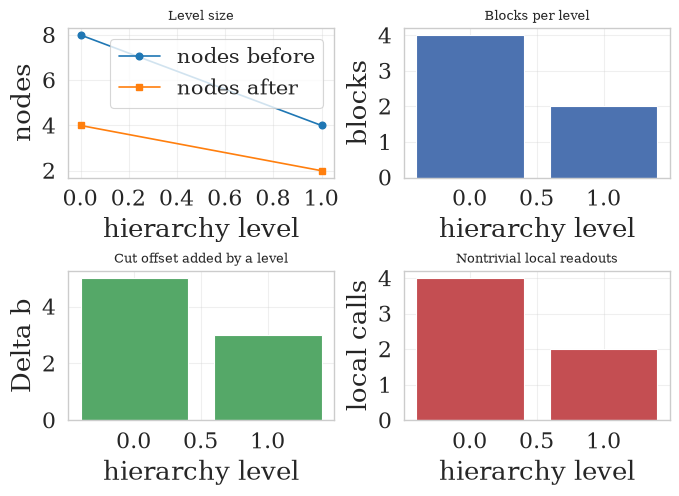

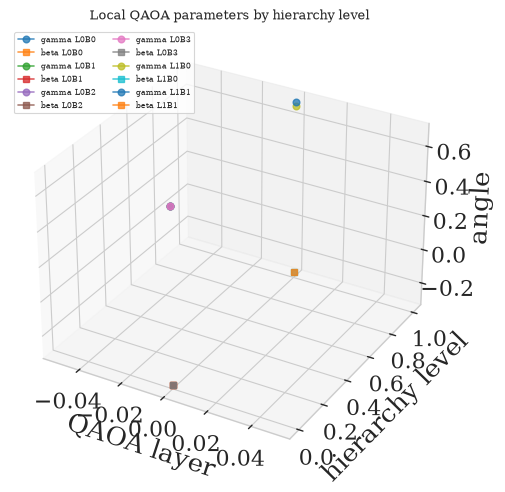

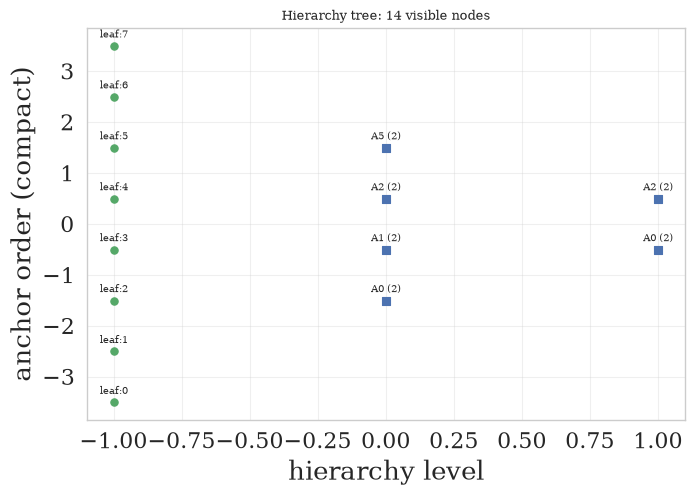

In [7]:
print("tree roots:", solver.hierarchy_tree["roots"])
print("levels:", solver.levels_completed, "primitive reductions:",
      solver.primitive_reductions_completed)
print("b:", solver.final_cut_offset, "Ising constant:", solver.final_ising_constant)
overview = tools.plot_hierarchy_overview(solver, {"style": {"figsize": [7,5]}})
parameters = tools.plot_hierarchy_parameters_3d(solver, {"style": {"figsize": [7,5]}})
tree = tools.plot_hierarchy_tree(solver, {"style": {"figsize": [7,5]}})
print("plots:", type(overview).__name__, type(parameters).__name__, type(tree).__name__)
assert overview.qa_record.algorithm_type == "qaoa_in_qaoa_hierarchy_overview"

## 7. Saving and reloading

In [8]:
with tempfile.TemporaryDirectory(prefix="hierarchy_save_") as tmp:
    save = {
        "path": str(Path(tmp) / "results"),
        "atts": ["solution", "cut_value", "hierarchy_history", "block_patterns",
                 "parameter_trajectory", "hierarchy_tree"],
        "filename": "hierarchy",
        "save_original_data": [],
        "makedir": True,
        "savedir": True,
    }
    saved = tools.save_result(solver, save)
    loaded = tools.load_result(saved.primary)
    print("saved:", saved.primary)
    print("loaded:", loaded.get("algorithm_type"))
    assert loaded.get("algorithm_type") == "qaoa_in_qaoa_cpu"
    assert loaded.get("hierarchy_tree") is not None

saved: C:\Users\Alexey\AppData\Local\Temp\hierarchy_save_ywipfe50\results\hierarchy\hierarchy.json
loaded: qaoa_in_qaoa_cpu


## 8. Summary

In [9]:
print("version:", QA_max_cut_lib.__version__)
print("control projection: ok")
print("multiple hierarchy levels: ok")
print("CPU parallel CLI: ok")
print("readout budget: ok")
print("tree/plots/save: ok")
print("GPU branch checked:", gpu_available())

version: 0.1.0a7
control projection: ok
multiple hierarchy levels: ok
CPU parallel CLI: ok
readout budget: ok
tree/plots/save: ok
GPU branch checked: True
